# Лабораторная работа №1
## Низкоуровневый анализ, предобработка текста и статистическое языковое моделирование

**Датасет (сквозной проект):** корпус гайдов [keqingmains.com](https://keqingmains.com) —
энциклопедия билдов Genshin Impact. Скрейпер `scrape_kqm.py` (переиспользован из
лабораторной работы по RAG) скачивает страницы в кеш `raw/*.html` — работаем с
**сырым HTML без какой-либо предобработки**: теги, скрипты, стили и сущности
остаются в данных, вся чистка делается в этом ноутбуке (шаг 4).

* **Текстовая колонка** — HTML-тело страницы гайда; класс и персонаж читаются
  из имени файла (`full-albedo.html`);
* **Целевой класс** — префикс файла: `full` (полный гайд) / `quick` (quick-гайд).
  Тематические статьи `misc` (2 шт.) исключены: класс из двух документов
  не годится для стратификации. Страницы-заглушки сайта («Extended Guide is
  currently in progress / needs an author») отбрасываются при загрузке.

**План:** 1) стратифицированный сплит 80/20 → 2) EDA на train → 3) инвентаризация
шума → 4) конвейер очистки на `re` → 5) стемминг vs лемматизация → 6) Левенштейн
(оптимизация по памяти) → 7) N-граммная модель с `[UNK]` → 8) сглаживание и
перплексия → 9) генерация Марковской цепью.

In [1]:
import os, re, json, time, math, random, collections
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

SEED = 42
plt.rcParams['figure.dpi'] = 110

for pkg in ('stopwords', 'wordnet', 'omw-1.4'):
    nltk.download(pkg, quiet=True)
print('nltk data ok, nltk', nltk.__version__)

nltk data ok, nltk 3.10.4


## Шаг 1. Загрузка датасета и стратифицированный сплит 80/20

Документы — сырые HTML-страницы из кеша скрейпера (`raw/`): класс `full`/`quick`
и слаг персонажа читаются из имени файла, misc-статьи не берём, заглушки сайта
отбрасываем по маркеру. Стратификация вручную: индексы группируются по классу,
каждая группа перемешивается с фиксированным зерном, в train идёт 80% группы —
пропорции классов в train/test гарантированно совпадают.

In [2]:
def visible_text(html):
    # черновой видимый текст: блоки script/style/svg и все теги срезаны,
    # сущности ещё не декодированы (это задача конвейера шага 4)
    t = re.sub(r'(?is)<(script|style|noscript|svg)[\s\S]*?</\1>', ' ', html)
    t = re.sub(r'<[^>]+>', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def load_corpus(raw_dir='raw'):
    # сырые HTML из кеша скрейпера; класс/персонаж — из имени файла
    docs, stubs = [], []
    for name in sorted(os.listdir(raw_dir)):
        if not name.endswith('.html'):
            continue
        dtype, slug = name[:-5].split('-', 1)
        if dtype not in ('full', 'quick'):          # misc-статьи не берём
            continue
        html = open(os.path.join(raw_dir, name), encoding='utf-8').read()
        # заглушки сайта: извещение вместо гайда, либо видимый текст ~ один
        # каркас страницы (< 2000 символов контента)
        if (re.search(r'Extended Guide\s+(is currently|needs an author)', html)
                or len(visible_text(html)) < 2000):
            stubs.append(name[:-5])
            continue
        docs.append({'file': name[:-5], 'type': dtype,
                     'character': slug, 'html': html})
    return docs, stubs

docs, stubs = load_corpus()
by_class = collections.Counter(d['type'] for d in docs)
print(f'датасет: {len(docs)} документов, классы: {dict(by_class)}')
print(f'отброшено заглушек сайта: {len(stubs)} (например, {stubs[:3]})')
print(f'суммарный объём: {sum(len(d["html"]) for d in docs):,} символов сырого HTML')

def stratified_split(docs, test_size=0.2, seed=SEED):
    rng = random.Random(seed)
    train_i, test_i = [], []
    groups = collections.defaultdict(list)
    for i, d in enumerate(docs):
        groups[d['type']].append(i)
    for idxs in groups.values():
        idxs = idxs[:]
        rng.shuffle(idxs)
        k = round(len(idxs) * (1 - test_size))
        train_i += idxs[:k]
        test_i += idxs[k:]
    return [docs[i] for i in train_i], [docs[i] for i in test_i]

train, test = stratified_split(docs)
tr = collections.Counter(d['type'] for d in train)
te = collections.Counter(d['type'] for d in test)
print(f'train: {len(train)} {dict(tr)}')
print(f'test : {len(test)} {dict(te)}')
print(f'доля full: train {tr["full"]/len(train):.1%} | test {te["full"]/len(test):.1%}'
      '  <- стратификация сохранила пропорцию классов')

датасет: 189 документов, классы: {'full': 68, 'quick': 121}
отброшено заглушек сайта: 57 (например, ['full-aino', 'full-alhaitham', 'full-alyosha'])
суммарный объём: 56,484,031 символов сырого HTML
train: 151 {'full': 54, 'quick': 97}
test : 38 {'full': 14, 'quick': 24}
доля full: train 35.8% | test 36.8%  <- стратификация сохранила пропорцию классов


## Шаг 2. Разведочный анализ — строго на обучающей выборке

Количество документов, средняя длина текстов в словах и символах, распределения
длин и частоты топ-30 стоп-слов (список NLTK для английского). Длины считаем по
**видимому тексту** (черновое срезание тегов — чтобы длина отражала контент,
а не HTML-каркас); полноценная очистка сырого HTML — в шаге 4.

документов в train: 151
средняя длина (видимый текст): 7,845 слов / 48,093 символов
медиана: 6,612 слов / 39,788 символов
диапазон: 1,787–38,289 слов


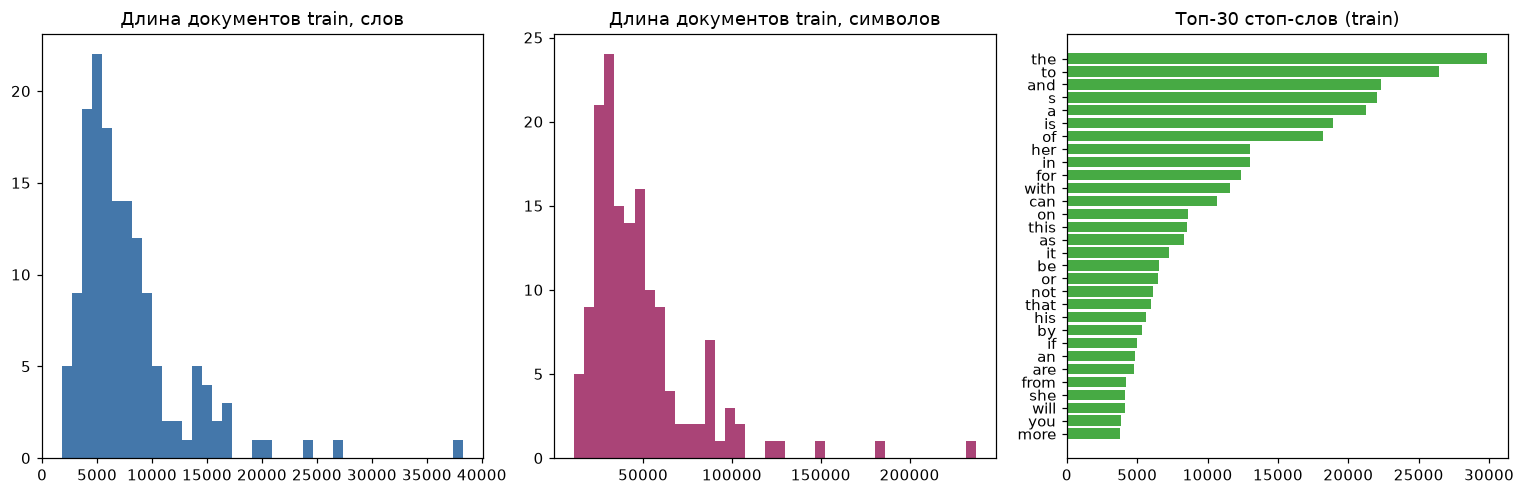

разных стоп-слов встречено: 160, покрытие топ-30: 78% всех стоп-слов


In [3]:
for d in docs:
    d['text'] = visible_text(d['html'])   # visible_text — из шага 1

n_words = [len(d['text'].split()) for d in train]
n_chars = [len(d['text']) for d in train]
print(f'документов в train: {len(train)}')
print(f'средняя длина (видимый текст): {sum(n_words)/len(n_words):,.0f} слов / '
      f'{sum(n_chars)/len(n_chars):,.0f} символов')
print(f'медиана: {sorted(n_words)[len(n_words)//2]:,} слов / '
      f'{sorted(n_chars)[len(n_chars)//2]:,} символов')
print(f'диапазон: {min(n_words):,}–{max(n_words):,} слов')

STOP = set(stopwords.words('english'))
sw_freq = collections.Counter(
    w for d in train for w in re.findall(r"[a-z']+", d['text'].lower())
    if w in STOP)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
ax[0].hist(n_words, bins=40, color='#4477aa')
ax[0].set_title('Длина документов train, слов')
ax[1].hist(n_chars, bins=40, color='#aa4477')
ax[1].set_title('Длина документов train, символов')
top30 = sw_freq.most_common(30)
labels, vals = zip(*top30)
ax[2].barh(range(len(top30)), vals, color='#47aa44')
ax[2].set_yticks(range(len(top30)), labels)
ax[2].invert_yaxis()
ax[2].set_title('Топ-30 стоп-слов (train)')
plt.tight_layout()
plt.savefig('eda_train.png', bbox_inches='tight')
plt.show()
print(f'разных стоп-слов встречено: {len(sw_freq)}, '
      f'покрытие топ-30: {sum(vals)/sum(sw_freq.values()):.0%} всех стоп-слов')

## Шаг 3. Инвентаризация шума домена

Датасет — сырые HTML-страницы WordPress, поэтому шум делится на два слоя:
**(1) шум разметки** — теги, блоки `<script>/<style>/<svg>`, `<head>`,
комментарии, каркас страницы, HTML-сущности — и **(2) шум содержимого**,
который останется после снятия разметки: changelog-строки «… Updated for
Version …» (в full-гайдах — списки правок), повторяющиеся на каждой странице
извещение «Please link this guide…» и cookie-хвост с кредитами, ники
художников `@username`, сырые URL, игровые числа и скейлы (`100%`, `0.8`,
`80/90`), декоративные символы ★♠♥. Markdown-разметки, бэктик-кода и
экранирований в корпусе нет **по построению** — конвертация HTML→markdown
не делалась.

In [4]:
html_joined = '\n'.join(d['html'] for d in train)
txt_joined = '\n'.join(d['text'] for d in train)     # видимый текст из шага 2

MARKUP = collections.OrderedDict([
    ('HTML-теги (все)',                  r'</?[a-zA-Z][a-zA-Z0-9]*(\s[^>\n]*)?/?>'),
    ('блоки <script>…</script> (JS)',    r'(?is)<script[\s\S]*?</script>'),
    ('блоки <style>…</style> (CSS)',     r'(?is)<style[\s\S]*?</style>'),
    ('блоки <svg>…</svg> (иконки)',      r'(?is)<svg[\s\S]*?</svg>'),
    ('HTML-комментарии <!--…-->',        r'<!--[\s\S]*?-->'),
    ('каркас <header>/<nav>/<footer>',   r'(?is)<(header|nav|footer)[\s\S]*?</\1>'),
    ('HTML-сущности &amp; &#8217; …',    r'&[a-zA-Z#0-9]+;'),
    ('надстрочные сноски <sup>1</sup>',  r'(?i)<sup>\d{1,2}</sup>'),
    ('атрибуты-ссылки href=/src=',       r'(?:href|src)="[^"]+"'),
])
CONTENT = collections.OrderedDict([
    ('changelog «Updated for Version…»', r'Updated for Version'),
    ('извещение «Please link this guide…»', r'Please link this guide'),
    ('ники художников @username',        r'(?<![a-zA-Z0-9])@[a-zA-Z0-9_]{3,}'),
    ('cookie-хвост «Update cookie preferences»', r'Update cookie preferences'),
    ('сырые URL в тексте',               r'https?://[^\s<>"<>]+'),
    ('игровые числа и скейлы',           r'\b\d+(?:[.,]\d+)?(?:\s*/\s*\d+)?%?\b'),
    ('декоративные символы ★♠♣♥♦',       r'[★☆♠♣♥♦♡♤♧♢✦✧❖]'),
])
ABSENT = collections.OrderedDict([
    ('markdown-разметка ** ##',          r'(?m)\*\*|^#{1,6} '),
    ('бэктик-код `…`',                   r'`[^`\n]+`'),
    ('экранирования \\- \\~',            r'\\[-~*_#.>|()]'),
])

def table(title, patterns, source, unit):
    print(f'\n{title}')
    for label, pat in patterns.items():
        ms = [m.group(0) for m in re.finditer(pat, source)]
        ex = f'   пример: {str(ms[0])[:44]!r}' if ms else ''
        print(f'{label:38s}{len(ms):>18,}{ex}')
    print(f'{"(считаем на " + unit + ")":>60s}')

table('HTML-разметка', MARKUP, html_joined, 'html')
table('Шум содержимого (видимый текст)', CONTENT, txt_joined, 'text')
table('Отсутствует в построении', ABSENT, txt_joined, 'text')

def show_ctx(source, pat, title, k=3, width=72):
    print('\n--- ' + title)
    for m in list(re.finditer(pat, source))[:k]:
        s = max(0, m.start() - 30)
        print('   …' + source[s:m.end() + 30].replace('\n', '⏎')[:width] + '…')

show_ctx(html_joined, r'(?i)<h[23][^>]*>[^<]{1,40}', 'заголовки в HTML')
show_ctx(html_joined, r'(?is)<script[\s\S]{0,120}', 'script-блоки')
show_ctx(txt_joined, r'Updated for Version\s+\S+', 'changelog-строки')
show_ctx(txt_joined, r'https?://[^\s<>"<>]+', 'URL-кредиты')


HTML-разметка


HTML-теги (все)                                  495,259   пример: '<html lang="en-US">'
блоки <script>…</script> (JS)                      3,935   пример: '<script type="application/ld+json" class="yo'


блоки <style>…</style> (CSS)                       1,538   пример: "<style id='filebird-block-filebird-gallery-s"
блоки <svg>…</svg> (иконки)                        2,416   пример: '<svg xmlns="http://www.w3.org/2000/svg" view'
HTML-комментарии <!--…-->                          1,904   пример: '<!-- This site is optimized with the Yoast S'
каркас <header>/<nav>/<footer>                       658   пример: '<header class="site-header has-inline-mobile'
HTML-сущности &amp; &#8217; …                     24,908   пример: '&#039;'
надстрочные сноски <sup>1</sup>                      948   пример: '<sup>1</sup>'


атрибуты-ссылки href=/src=                        39,819   пример: 'href="https://gmpg.org/xfn/11"'
                                           (считаем на html)

Шум содержимого (видимый текст)
changelog «Updated for Version…»                     147   пример: 'Updated for Version'
извещение «Please link this guide…»                  151   пример: 'Please link this guide'
ники художников @username                             71   пример: '@yeurei'
cookie-хвост «Update cookie preferences»               151   пример: 'Update cookie preferences'
сырые URL в тексте                                    22   пример: 'https://docs.google.com/spreadsheets/d/1PvqQ'


игровые числа и скейлы                            32,643   пример: '3.8'
декоративные символы ★♠♣♥♦                         1,269   пример: '★'
                                           (считаем на text)

Отсутствует в построении
markdown-разметка ** ##                                6   пример: '**'
бэктик-код `…`                                         0
экранирования \- \~                                    0
                                           (считаем на text)

--- заголовки в HTML
   …block-column is-layout-flow">⏎<h3 class="wp-block-heading has-text-align…
   …block-column is-layout-flow">⏎<h3 class="wp-block-heading has-text-align…
   … to another character.</p>⏎⏎⏎⏎<h3 class="wp-block-heading">Shielding</h3…

--- script-блоки
   …ta2" content="30 minutes" />⏎	<script type="application/ld+json" class="…
   …er=1793952467' media='all' />⏎<script id='wpml-cookie-js-extra'>⏎var wpm…
   …s":1,"path":"\/"}};⏎</script>⏎<script src='https://keqingmains.com/wp-co…

--- changelog

## Шаг 4. Конвейер очистки на `re`

Порядок правил важен: сначала вырезаются целые блоки (`<script>/<style>/<svg>`,
`<head>`, `<!DOCTYPE>`, комментарии, каркас `<header>/<nav>/<footer>`,
служебные блоки scrollTop/skip-link), затем блочные теги превращаются в
переводы строк (границы абзацев/строк таблиц), ячейки таблиц — в пробелы, и
только потом снимаются остальные теги: текст заголовков и ячеек сохраняется.
После разметки чинится текст: сущности декодируются (именованные — из словаря,
числовые — через `chr`), changelog-строки и списки правок удаляются целиком,
повторяющиеся извещение и cookie-хвост режутся по маркерам, ники `@username`
вырезаются, URL → `[URL]`, числа → `[NUM]`. Тотального «удалить всё, кроме
букв» нет — каждому типу шума своё правило. В конце документ оборачивается
в `<s>` … `</s>`.

In [5]:
ENT = {'&amp;': '&', '&lt;': '<', '&gt;': '>', '&quot;': '"',
       '&nbsp;': ' ', '&laquo;': '«', '&raquo;': '»'}

RULES = [
    ('блоки <script>…</script> (JS, трекеры)',
     r'(?is)<script[\s\S]*?</script>', ''),
    ('блоки <style>…</style> (CSS)',
     r'(?is)<style[\s\S]*?</style>', ''),
    ('блоки <svg>/<noscript>/<iframe> (иконки, заглушки)',
     r'(?is)<(svg|noscript|iframe)[\s\S]*?</\1>', ''),
    ('блоки <head>…</head> (title, meta, link)',
     r'(?is)<head[\s\S]*?</head>', ''),
    ('декларации <!DOCTYPE …>',
     r'<![^>]*>', ''),
    ('HTML-комментарии <!--…-->',
     r'<!--[\s\S]*?-->', ''),
    ('каркас страницы <header>/<nav>/<footer>',
     r'(?is)<(header|nav|footer)[\s\S]*?</\1>', ''),
    ('кнопка прокрутки наверх (scrollTop-блок)',
     r'(?is)<div[^>]*class="[^"]*scroll[^"]*"[^>]*>[\s\S]*?</div>', ''),
    ('скип-линк доступности «Skip to content»',
     r'(?is)<a[^>]*class="[^"]*skip[^"]*"[^>]*>[\s\S]*?</a>', ''),
    ('блочные теги -> перевод строки',
     r'(?i)</?(p|div|h[1-6]|li|tr|table|ul|ol|blockquote|br)\b[^>]*>', '\n'),
    ('ячейки таблиц </td> </th> -> пробел',
     r'(?i)</t[dh]>', ' '),
    ('остальные теги удаляются, текст внутри сохраняется',
     r'</?[a-zA-Z][a-zA-Z0-9]*(\s[^>]*)?/?>', ''),
    ('именованные HTML-сущности',
     r'&(amp|lt|gt|quot|nbsp|laquo|raquo);', lambda m: ENT[m.group(0)]),
    ('числовые HTML-сущности &#8217; -> символ',
     r'&#(\d+);', lambda m: chr(int(m.group(1)))),
    ('changelog-строка/блок «… Updated for Version …» (вся строка + список правок)',
     r'(?im)^.*\bUpdated for Version\b.*(?:\n(?!\s*$).*)*', ''),
    ('извещение «Please link this guide…» (на каждой странице)',
     r'(?im)^.*\bPlease link this guide\b.*(?:\n(?!\s*$).*)*', ''),
    ('хвост сайта: cookie-баннер и кредиты до конца документа',
     r'(?s)Update cookie preferences[\s\S]*$', ''),
    ('ники художников @username (кредиты артов)',
     r'(?<![a-zA-Z0-9])@[a-zA-Z0-9_]{2,}', ''),
    ('сырой URL -> [URL]',
     r'https?://\S+', '[URL]'),
    ('декоративные символы ★♠♣♥♦',
     r'[★☆♠♣♥♦♡♤♧♢✦✧❖]', ''),
    ('числа/проценты/скейлы 100%, 0.8, 80/90 -> [NUM]',
     r'\b\d+(?:[.,]\d+)?(?:\s*/\s*\d+(?:[.,]\d+)?)?%?', '[NUM]'),
    ('пустые скобки-огрызки () [] {}',
     r'[\(\[\{]\s*[\)\]\}]', ''),
]

def clean_text(html):
    # возвращает текст, обёрнутый в <s>…</s>, и счётчики срабатываний правил
    hits = collections.Counter()
    out = html
    for label, pat, repl in RULES:
        hits[label] = len(re.findall(pat, out))
        out = re.sub(pat, repl, out)
    out = re.sub(r'[ \t]+', ' ', out)
    out = re.sub(r' ?\n ?', '\n', out)
    out = re.sub(r'\n{2,}', '\n', out).strip()
    out = out.replace('’', "'")    # типографский апостроф: albedo’s -> albedo's
    return f'<s> {out} </s>', hits

t0 = time.time()
total_hits = collections.Counter()
for d in train:
    d['clean'], h = clean_text(d['html'])
    total_hits.update(h)
for d in test:
    d['clean'], _ = clean_text(d['html'])

# выгрузка до/после: «до» — сырой raw/<имя>.html, «после» — cleaned/<имя>.txt
os.makedirs('cleaned', exist_ok=True)
for d in train + test:
    with open(os.path.join('cleaned', d['file'] + '.txt'), 'w', encoding='utf-8') as f:
        f.write(d['clean'])
print(f'сохранены пары до/после: raw/<имя>.html -> cleaned/<имя>.txt '
      f'({len(train) + len(test)} шт.)')

print(f'очистка {len(train)+len(test)} документов за {time.time()-t0:.1f} с;'
      ' правила, сработавшие чаще всего:')
for label, n in total_hits.most_common(6):
    print(f'   {n:>8,}  {label}')

doc = next((d for d in train if d['file'] == 'quick-albedo'), train[0])
s = doc['html'].find('Albedo is a')
print(f'\nДо обработки')
print(doc['html'][s - 350:s + 300], '\n')
print('После')
print(doc['clean'][:400])

TOKEN_RE = re.compile(r"<s>|</s>|\[[a-z]+\]|[a-z]+(?:'[a-z]+)?")

def tokenize(clean):
    return TOKEN_RE.findall(clean.lower())

for d in train + test:
    d['tokens'] = tokenize(d['clean'])

tr_tokens = [t for d in train for t in d['tokens']]
freq = collections.Counter(tr_tokens)
print(f'\nтокенов в train: {len(tr_tokens):,}, словарь: {len(freq):,} типов')
print('топ-10 токенов после очистки:', freq.most_common(10))

сохранены пары до/после: raw/<имя>.html -> cleaned/<имя>.txt (189 шт.)
очистка 189 документов за 5.0 с; правила, сработавшие чаще всего:
    202,761  блочные теги -> перевод строки
    187,650  остальные теги удаляются, текст внутри сохраняется
     36,598  числа/проценты/скейлы 100%, 0.8, 80/90 -> [NUM]
     26,313  ячейки таблиц </td> </th> -> пробел
     18,192  именованные HTML-сущности
      4,506  числовые HTML-сущности &#8217; -> символ

До обработки
m></h6>


<div class="wp-block-image">
<figure class="aligncenter size-full"><img decoding="async" width="1400" height="1024" src="https://kqm-uploads.keqingmains.com/wp-content/uploads/2026/02/Albedo_Splash_Art1.webp" alt="" class="wp-image-286047"/></figure></div>


<div style="height:50px" aria-hidden="true" class="wp-block-spacer"></div>



<p>Albedo is a 5★ Geo Sword character in <em>Genshin Impact</em> who specializes in consistent off-field Geo damage. Learn about Albedo’s best builds, best weapons, best artifacts, and best t


токенов в train: 1,158,802, словарь: 12,867 типов
топ-10 токенов после очистки: [('[num]', 36598), ('the', 29601), ('to', 25905), ('and', 21863), ('a', 21024), ('is', 18827), ('of', 18150), ('her', 13006), ('in', 12963), ('for', 11864)]


## Шаг 5. Сравнительная нормализация: стемминг vs лемматизация

Стеммер Портера режет аффиксы по правилам, лемматизатор WordNet ищет словарную
форму (для глагольных окончаний `-ing/-ed/-es` вызываем с `pos='v'`). Сравниваем
размер словаря до/после каждого способа и смотрим, какие слова схлопывает
стеммер (коллизии).

In [6]:
stemmer = PorterStemmer()
lemmer = WordNetLemmatizer()

def lemma(w):
    if w.endswith(('ing', 'ed', 'es')):
        return lemmer.lemmatize(w, 'v')
    return lemmer.lemmatize(w)

V_clean = set(freq)
V_stem = {stemmer.stem(w) for w in V_clean}
V_lemma = {lemma(w) for w in V_clean}
print(f'{"словарь":34s}{"типов":>10s}{"к исходному":>14s}')
print(f'{"до нормализации (после очистки)":34s}{len(V_clean):>10,}{"100%":>14s}')
print(f'{"после стемминга (Porter)":34s}{len(V_stem):>10,}{len(V_stem)/len(V_clean):>13.1%}')
print(f'{"после лемматизации (WordNet)":34s}{len(V_lemma):>10,}{len(V_lemma)/len(V_clean):>13.1%}')

sample = ['talents', 'scaling', 'gearing', 'characters', 'buffers', 'healing',
          'pyro', 'damage', 'enemies', 'weakness', 'buffed', 'units', 'shields', 'stages']
print('\nслово            стемминг         лемматизация')
for w in sample:
    print(f'{w:16s}{stemmer.stem(w):18s}{lemma(w)}')

stem_map = collections.defaultdict(set)
for w in V_clean:
    stem_map[stemmer.stem(w)].add(w)
collisions = sorted((v for v in stem_map.values() if len(v) > 2), key=len, reverse=True)[:8]
print('\nколлизии стеммера (разные слова -> один стем):')
for group in collisions:
    print('  ', sorted(group)[:8])

словарь                                типов   к исходному
до нормализации (после очистки)       12,867          100%
после стемминга (Porter)               8,724        67.8%
после лемматизации (WordNet)          10,138        78.8%

слово            стемминг         лемматизация
talents         talent            talent
scaling         scale             scale
gearing         gear              gear
characters      charact           character
buffers         buffer            buffer
healing         heal              heal
pyro            pyro              pyro
damage          damag             damage
enemies         enemi             enemies
weakness        weak              weakness
buffed          buf               buff
units           unit              unit
shields         shield            shield
stages          stage             stag

коллизии стеммера (разные слова -> один стем):
   ['general', 'generalized', 'generalizes', 'generally', 'generate', 'generated', 'generates', 'genera

## Шаг 6. Поиск опечаток: расстояние Левенштейна с оптимизацией по памяти

Классическая матрица DP занимает `O(|a|·|b|)` памяти, но строка `i` зависит
только от строки `i-1` — храним **две строки** и разворачиваем DP по более
короткой строке: память `O(min(|a|,|b|))`. Дополнительно ранний выход: если
минимум по текущей строке превысил порог `max_d`, расстояние заведомо больше
порога (нужно только для скорости перебора пар, на корректность не влияет).

Сравниваем слова словаря train (частота ≥ 5, длина ≥ 4, без служебных токенов)
с расстоянием 1–2: это опечатки и разные формы одного слова.

In [7]:
def levenshtein(a, b, max_d=None):
    # двухрядная DP: O(min(|a|,|b|)) памяти; max_d — ранний выход
    if len(a) < len(b):
        a, b = b, a
    if max_d is not None and len(a) - len(b) > max_d:
        return max_d + 1
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i] + [0] * len(b)
        best = i
        for j, cb in enumerate(b, 1):
            cur[j] = min(prev[j] + 1,               # удаление
                         cur[j - 1] + 1,            # вставка
                         prev[j - 1] + (ca != cb))  # замена
            if cur[j] < best:
                best = cur[j]
        if max_d is not None and best > max_d:
            return max_d + 1
        prev = cur
    return prev[-1]

# санити-проверки реализации
assert levenshtein('kitten', 'sitting') == 3
assert levenshtein('flaw', 'lawn') == 2
assert levenshtein('', 'abc') == 3
assert levenshtein('same', 'same') == 0
print('проверки levenshtein пройдены (kitten->sitting=3, flaw->lawn=2)')

MIN_FREQ, MIN_LEN = 5, 4
words = {w: c for w, c in freq.items()
         if c >= MIN_FREQ and len(w) >= MIN_LEN and w[0] not in '<['}
buckets = collections.defaultdict(list)
for w in words:
    buckets[len(w)].append(w)

t0 = time.time()
pairs = []
lens = sorted(buckets)
for bi, l1 in enumerate(lens):
    for l2 in lens[bi:]:
        if l2 - l1 > 2:      # |Δдлин| > порога — дальше длины только растут
            break
        for a in buckets[l1]:
            for b in buckets[l2]:
                if a == b or (l1 == l2 and a > b):
                    continue
                d = levenshtein(a, b, max_d=2)
                if d in (1, 2):
                    pairs.append((d, words[a] * words[b], a, b))
print(f'слов в сравнении: {len(words):,}, пар с d=1..2: {len(pairs):,} '
      f'за {time.time()-t0:.1f} с')
print(f'  из них d=1: {sum(1 for p in pairs if p[0]==1):,}, '
      f'd=2: {sum(1 for p in pairs if p[0]==2):,}')

print('\nтоп-10 пар (сначала d=1, затем по произведению частот):')
print(f'{"слово A":16s}{"слово B":16s}{"d":>3s}{"freqA":>9s}{"freqB":>9s}')
for d, _, a, b in sorted(pairs, key=lambda p: (p[0], -p[1]))[:10]:
    print(f'{a:16s}{b:16s}{d:>3d}{words[a]:>9,}{words[b]:>9,}')

# топ-10 выше ранжирован по произведению частот - морфология всегда побеждает.
# профиль настоящей опечатки другой: редкое слово (freq<=2) на d=1 от частого
# (freq>=20), и его нет в словаре WordNet
from nltk.corpus import wordnet
in_dict = lambda w: bool(wordnet.synsets(w))
rare_w = [w for w, c in freq.items() if c <= 2 and len(w) >= 4 and w.isalpha()]
common_w = [w for w, c in freq.items() if c >= 20 and len(w) >= 4 and w.isalpha()]
typos = [(r, c) for r in rare_w for c in common_w
         if abs(len(r) - len(c)) <= 1 and levenshtein(r, c, max_d=1) == 1]
unknown = [(r, c, freq[r], freq[c]) for r, c in typos if not in_dict(r)]
print()
print('Ищем настоящие опечатки: редкое (freq<=2) на d=1 от частого (freq>=20)')
print(f'пар: {len(typos)}, из них без записи в WordNet: {len(unknown)}')
print('кандидаты в опечатки:')
for r, c, fr, fc in sorted(unknown, key=lambda t: -t[3])[:15]:
    print(f'   {r} (freq {fr})  ~  {c} (freq {fc})')

проверки levenshtein пройдены (kitten->sitting=3, flaw->lawn=2)


слов в сравнении: 5,547, пар с d=1..2: 22,404 за 42.0 с
  из них d=1: 2,470, d=2: 19,934

топ-10 пар (сначала d=1, затем по произведению частот):
слово A         слово B           d    freqA    freqB
team            teams             1    5,798    6,786
attack          attacks           1    4,177    2,863
than            that              1    1,917    5,907
buff            buffs             1    3,739    2,661
skill           still             1    6,309    1,503
rotation        rotations         1    5,268    1,128
well            will              1    1,265    4,116
character       characters        1    2,209    1,706
teams           team's            1    6,786      527
provide         provides          1    1,302    2,552



Ищем настоящие опечатки: редкое (freq<=2) на d=1 от частого (freq>=20)
пар: 1136, из них без записи в WordNet: 180
кандидаты в опечатки:
   damager (freq 1)  ~  damage (freq 10653)
   skil (freq 1)  ~  skill (freq 6309)
   ehen (freq 1)  ~  when (freq 3761)
   cryos (freq 1)  ~  cryo (freq 3691)
   dedro (freq 2)  ~  dendro (freq 2829)
   dendo (freq 1)  ~  dendro (freq 2829)
   xinqiu (freq 1)  ~  xingqiu (freq 1917)
   theirs (freq 1)  ~  their (freq 1781)
   rcommended (freq 1)  ~  recommended (freq 1672)
   favonis (freq 1)  ~  favonius (freq 1633)
   thee (freq 2)  ~  these (freq 1619)
   ahold (freq 1)  ~  hold (freq 1599)
   everya (freq 1)  ~  every (freq 1510)
   doth (freq 1)  ~  both (freq 1488)
   thee (freq 2)  ~  they (freq 1439)


## Шаг 7. Статистическая N-граммная модель

Обучение на токенах очищенного train. Словарь явный: слова с частотой < 2
считаются редкими и вместе с любыми OOV-словами теста отображаются в `[UNK]`.
Для интерполяции и сглаживания модель держит счётчики k-грамм **всех порядков**
k = 1..n (считаются за один проход по позициям); последовательности паддятся
`<s>` × (n−1) слева и `</s>` справа.

In [8]:
class NGramLM:
    # N-граммная модель: счётчики counts[k] для всех порядков 1..n

    def __init__(self, n, min_freq=2):
        self.n, self.min_freq = n, min_freq

    def fit(self, token_lists):
        cnt = collections.Counter(t for toks in token_lists for t in toks)
        self.vocab = {w for w, c in cnt.items() if c >= self.min_freq} | {'[UNK]'}
        self.word2id = {w: i for i, w in enumerate(sorted(self.vocab))}
        unk = self.word2id['[UNK]']
        pad = [self.word2id['<s>']] * (self.n - 1)
        eos = self.word2id['</s>']
        counts = {k: collections.Counter() for k in range(1, self.n + 1)}
        for toks in token_lists:
            ids = pad + [self.word2id.get(t, unk) for t in toks] + [eos]
            for i in range(self.n - 1, len(ids)):
                for k in range(1, self.n + 1):
                    counts[k][tuple(ids[i - k + 1:i + 1])] += 1
        self.counts = counts
        self.total = sum(counts[1].values())   # число предсказываемых позиций
        return self

t0 = time.time()
bigram = NGramLM(2).fit([d['tokens'] for d in train])
t1 = time.time()
trigram = NGramLM(3).fit([d['tokens'] for d in train])
t2 = time.time()
print(f'словарь модели: {len(bigram.vocab):,} типов (freq>={bigram.min_freq}, +[UNK])')
print(f'биграмм:  {len(bigram.counts[2]):,} типов ({bigram.total:,} вхождений), fit {t1-t0:.1f} с')
print(f'триграмм: {len(trigram.counts[3]):,} типов, биграмм в ней {len(trigram.counts[2]):,}, '
      f'униграмм {len(trigram.counts[1]):,}, fit {t2-t1:.1f} с')
unk_share = trigram.counts[1][(trigram.word2id['[UNK]'],)] / trigram.total
print(f'доля [UNK] в train-позициях: {unk_share:.2%}')

словарь модели: 9,099 типов (freq>=2, +[UNK])
биграмм:  236,628 типов (1,158,953 вхождений), fit 1.0 с
триграмм: 625,484 типов, биграмм в ней 236,628, униграмм 9,099, fit 1.6 с
доля [UNK] в train-позициях: 0.33%


## Шаг 8. Сглаживание и перплексия

Без сглаживания любая невиденная n-грамма получает `P = 0`, правдоподобие
теста обнуляется, перплексия формально бесконечна. Реализуем **Лаплас (add-1)**:
`P = (c+1)/(N_ctx+V)` — и **линейную интерполяцию** (Jelinek–Mercer):
`P = λ_n·P_n + λ_{n-1}·P_{n-1} + … + λ_1·P_1`, каждый порядок смотрит в свои
счётчики `counts[k]`. Перплексия — через логарифм правдоподобия:
`PPL = 2^(−(1/N)·Σ log₂ P(w_i|h_i))`, переполнения исключено.

In [9]:
LAM = {2: (0.7, 0.3), 3: (0.6, 0.3, 0.1)}   # веса порядков n, n-1, ..., 1

def prob_none(lm, ctx, w):
    # MLE без сглаживания: 0 для невиденных n-грамм
    c = lm.counts[lm.n].get(ctx + (w,), 0)
    tot = lm.counts[lm.n - 1].get(ctx, 0)
    return c / tot if tot else 0.0

def prob_laplace(lm, ctx, w):
    V = len(lm.vocab)
    c = lm.counts[lm.n].get(ctx + (w,), 0)
    tot = lm.counts[lm.n - 1].get(ctx, 0)
    return (c + 1) / (tot + V)

def prob_interp(lm, ctx, w):
    p = 0.0
    for k in range(lm.n, 0, -1):
        lam = LAM[lm.n][lm.n - k]
        if k > 1:
            pref = ctx[-(k - 1):]
            num = lm.counts[k].get(pref + (w,), 0)
            den = lm.counts[k - 1].get(pref, 0)
        else:
            num = lm.counts[1].get((w,), 0)
            den = lm.total
        if den:
            p += lam * num / den
    return p if p > 0 else 1.0 / len(lm.vocab)

PROB = {'none': prob_none, 'laplace': prob_laplace, 'interp': prob_interp}

def seq_ids(lm, toks):
    pad = [lm.word2id['<s>']] * (lm.n - 1)
    unk = lm.word2id['[UNK]']
    return pad + [lm.word2id.get(t, unk) for t in toks] + [lm.word2id['</s>']]

def perplexity(lm, token_lists, method='interp'):
    # PPL = 2^(-(1/N) * sum log2 P) — в логарифмах, без переполнения
    pfn = PROB[method]
    logp, n = 0.0, 0
    for toks in token_lists:
        ids = seq_ids(lm, toks)
        for i in range(lm.n - 1, len(ids)):
            p = pfn(lm, tuple(ids[i - lm.n + 1:i]), ids[i])
            if p <= 0.0:
                return float('inf')
            logp += math.log2(p)
            n += 1
    return 2.0 ** (-logp / n)

test_lists = [d['tokens'] for d in test]
rows = []
for name, lm in (('биграмма N=2', bigram), ('триграмма N=3', trigram)):
    row = {'модель': name}
    for m in ('none', 'laplace', 'interp'):
        row[m] = perplexity(lm, test_lists, m)
    rows.append(row)

fmt = lambda v: '∞' if v == float('inf') else f'{v:,.0f}'
print(f'{"модель":14s}{"без сглаживания":>18s}{"Лаплас add-1":>15s}{"интерполяция":>15s}')
for r in rows:
    print(f'{r["модель"]:14s}{fmt(r["none"]):>18s}{fmt(r["laplace"]):>15s}{fmt(r["interp"]):>15s}')
print('\n(перплексия на test; ∞ = в тесте есть невиденные n-граммы, P=0 -> правдоподобие 0)')

модель           без сглаживания   Лаплас add-1   интерполяция
биграмма N=2                   ∞            517            132
триграмма N=3                  ∞          2,573             95

(перплексия на test; ∞ = в тесте есть невиденные n-граммы, P=0 -> правдоподобие 0)


## Шаг 9. Генерация текстов Марковской цепью

Сэмплирование следующего слова из интерполяционного распределения триграмной
модели: старт с `<s>`, остановка при выпадении `</s>` или на 40-м токене.

In [10]:
rng = random.Random(SEED)

def generate(lm, max_len=40):
    ids = [lm.word2id['<s>']] * (lm.n - 1)
    out = []
    for _ in range(max_len):
        ctx = tuple(ids[-(lm.n - 1):])
        cand, weights = [], []
        for w, i in lm.word2id.items():
            if w == '<s>':
                continue
            p = prob_interp(lm, ctx, i)
            if p > 0:
                cand.append(w)
                weights.append(p)
        w = rng.choices(cand, weights=weights, k=1)[0]
        if w == '</s>':
            break
        out.append(w)
        ids.append(lm.word2id[w])
    return ' '.join(out)

print('5 сгенерированных текстов (триграмная модель, интерполяция):\n')
for i in range(5):
    print(f'--- текст {i+1}')
    print(generate(trigram), '\n')

5 сгенерированных текстов (триграмная модель, интерполяция):

--- текст 1


official art by [num] personal dps this and granting a generous amount by [UNK] presence it also involves multiple [num] star recommended gear an to extend forgo a short is split time xingqiu yelan furina kazuha this slot that recurve 

--- текст 2


prune atk gameplay difficulty desired difficult c combo sacrificial fragments is generally good value is lower compared to c flex xianyun's burst increases the rely on elemental application e g crescent rotation set shinobu or dori would be better in 

--- текст 3


mualani is on the geo characters you love em a crit rate secondary stat and dps yae's best weapon r [num] r mouun's moon duckweed in fights note that with the dual carry composition this thus forces qiqi into a 

--- текст 4


skirk is not necessarily [UNK] acquiring [num] she will see considerably boosts skill those enemies but can only pyro and energy out geo resonance furina's burst is pre c er with is extremely niche and even if the elemental burst 

--- текст 5


alhaitham is a total of [num] different kinds of aid the most is in the downtime at the expense of skirk's kit with a healer if you can't dash walk out of depend providing em while kazuha's ascension yoimiya to 



## Сводка результатов

In [11]:
summary = {
    'docs_total': len(docs), 'train': len(train), 'test': len(test),
    'avg_words_train': round(sum(n_words) / len(n_words)),
    'avg_chars_train': round(sum(n_chars) / len(n_chars)),
    'vocab_clean': len(V_clean), 'vocab_stem': len(V_stem), 'vocab_lemma': len(V_lemma),
    'lev_pairs_d1': sum(1 for p in pairs if p[0] == 1),
    'lev_pairs_d2': sum(1 for p in pairs if p[0] == 2),
    'vocab_lm': len(bigram.vocab),
    'bigram_types': len(bigram.counts[2]), 'trigram_types': len(trigram.counts[3]),
    'ppl_bigram_laplace': round(rows[0]['laplace']),
    'ppl_bigram_interp': round(rows[0]['interp']),
    'ppl_trigram_laplace': round(rows[1]['laplace']),
    'ppl_trigram_interp': round(rows[1]['interp']),
}
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "docs_total": 189,
  "train": 151,
  "test": 38,
  "avg_words_train": 7845,
  "avg_chars_train": 48093,
  "vocab_clean": 12867,
  "vocab_stem": 8724,
  "vocab_lemma": 10138,
  "lev_pairs_d1": 2470,
  "lev_pairs_d2": 19934,
  "vocab_lm": 9099,
  "bigram_types": 236628,
  "trigram_types": 625484,
  "ppl_bigram_laplace": 517,
  "ppl_bigram_interp": 132,
  "ppl_trigram_laplace": 2573,
  "ppl_trigram_interp": 95
}
